In [1]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file in [
            "train_regression.csv",
            "val_regression.csv",
            "test_regression.csv",
            "train.csv",
            "val.csv",
            "test.csv",
        ]:
            print(os.path.join(root, file))

/kaggle/input/datasets/rpghost/scaffold-regression/test_regression.csv
/kaggle/input/datasets/rpghost/scaffold-regression/val_regression.csv
/kaggle/input/datasets/rpghost/scaffold-regression/train_regression.csv


In [2]:
import pandas as pd

DATA_DIR = "/kaggle/input/datasets/rpghost/scaffold-regression"

train_df = pd.read_csv(f"{DATA_DIR}/train_regression.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val_regression.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test_regression.csv")

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"\n{name}: {df.shape}")
    print("Columns:", df.columns.tolist())
    print("Missing SMILES:", df["smiles"].isna().sum())
    print("Missing pIC50:", df["median_pIC50"].isna().sum())
    print(df["median_pIC50"].describe())


Train: (7402, 3)
Columns: ['inchi_key', 'smiles', 'median_pIC50']
Missing SMILES: 0
Missing pIC50: 0
count    7402.000000
mean        5.379885
std         0.918120
min         0.020000
25%         4.796561
50%         5.259637
75%         5.799993
max        10.677781
Name: median_pIC50, dtype: float64

Validation: (948, 3)
Columns: ['inchi_key', 'smiles', 'median_pIC50']
Missing SMILES: 0
Missing pIC50: 0
count    948.000000
mean       5.534218
std        1.088342
min        0.120000
25%        4.881903
50%        5.291108
75%        5.933784
max        9.318759
Name: median_pIC50, dtype: float64

Test: (1941, 3)
Columns: ['inchi_key', 'smiles', 'median_pIC50']
Missing SMILES: 0
Missing pIC50: 0
count    1941.000000
mean        5.429396
std         0.881996
min         1.000000
25%         4.853872
50%         5.275724
75%         5.823909
max         9.187087
Name: median_pIC50, dtype: float64


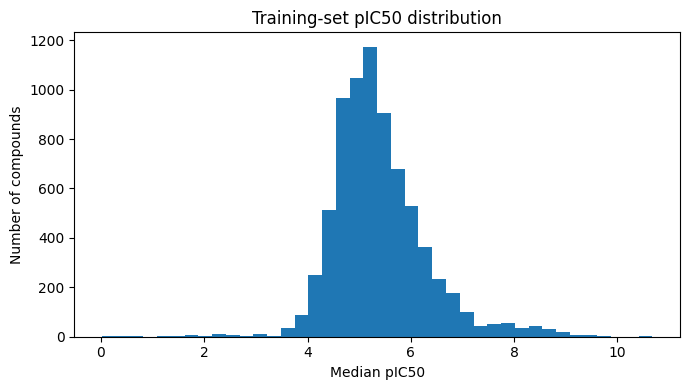

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.hist(train_df["median_pIC50"], bins=40)
plt.xlabel("Median pIC50")
plt.ylabel("Number of compounds")
plt.title("Training-set pIC50 distribution")
plt.tight_layout()
plt.show()

In [4]:
!pip install chemprop

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.3/154.3 kB 3.4 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 17.6 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 330.0/330.0 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 17.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 19.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.0/188.0 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.0/176.0 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.9/20.9 MB 18.1 MB/s eta 0:00:0000:0100:01


In [5]:
!chemprop --version

chemprop 2.3.1


In [ ]:
!chemprop train \
    --data-path "{DATA_DIR}/train_regression.csv" \
                  "{DATA_DIR}/val_regression.csv" \
                  "{DATA_DIR}/test_regression.csv" \
    --smiles-columns smiles \
    --target-columns median_pIC50 \
    --task-type regression \
    --metrics rmse mae r2 \
    --epochs 50 \
    --patience 7 \
    --batch-size 64 \
    --accelerator gpu \
    --devices 1 \
    --pytorch-seed 123 \
    --output-dir /kaggle/working/chemprop_regression

2026-10-14T10:28:03 - INFO:chemprop.cli.main - Running in mode 'train' with args: {'smiles_columns': ['smiles'], 'reaction_columns': None, 'no_header_row': False, 'num_workers': 0, 'batch_size': 64, 'accelerator': 'gpu', 'devices': '1', 'rxn_mode': 'REAC_DIFF', 'multi_hot_atom_featurizer_mode': 'V2', 'keep_h': False, 'add_h': False, 'ignore_stereo': False, 'reorder_atoms': False, 'molecule_featurizers': None, 'descriptors_path': None, 'descriptors_columns': None, 'no_descriptor_scaling': False, 'no_atom_feature_scaling': False, 'no_atom_descriptor_scaling': False, 'no_bond_feature_scaling': False, 'no_bond_descriptor_scaling': False, 'atom_features_path': None, 'atom_descriptors_path': None, 'bond_features_path': None, 'bond_descriptors_path': None, 'constraints_path': None, 'constraints_to_targets': None, 'use_cuikmolmaker_featurization': False, 'config_path': None, 'data_path': [PosixPath('/kaggle/input/datasets/rpghost/scaffold-regression/train_regression.csv'), PosixPath('/kaggle/i

In [7]:
import os

MODEL_DIR = "/kaggle/working/chemprop_regression"

for root, dirs, files in os.walk(MODEL_DIR):
    for file in files:
        if file.endswith(".pt"):
            print(os.path.join(root, file))

/kaggle/working/chemprop_regression/model_0/best.pt


In [8]:
BEST_MODEL = "/kaggle/working/chemprop_regression/model_0/best.pt"
RESULTS_DIR = "/kaggle/working/chemprop_regression/results"

os.makedirs(RESULTS_DIR, exist_ok=True)

In [9]:
!chemprop predict \
    -i "{DATA_DIR}/val_regression.csv" \
    -o "{RESULTS_DIR}/val_predictions.csv" \
    -s smiles \
    --model-paths "{BEST_MODEL}" \
    --accelerator gpu \
    --devices 1

2026-10-14T10:32:54 - INFO:chemprop.cli.main - Running in mode 'predict' with args: {'smiles_columns': ['smiles'], 'reaction_columns': None, 'no_header_row': False, 'num_workers': 0, 'batch_size': 64, 'accelerator': 'gpu', 'devices': '1', 'rxn_mode': 'REAC_DIFF', 'multi_hot_atom_featurizer_mode': 'V2', 'keep_h': False, 'add_h': False, 'ignore_stereo': False, 'reorder_atoms': False, 'molecule_featurizers': None, 'descriptors_path': None, 'descriptors_columns': None, 'no_descriptor_scaling': False, 'no_atom_feature_scaling': False, 'no_atom_descriptor_scaling': False, 'no_bond_feature_scaling': False, 'no_bond_descriptor_scaling': False, 'atom_features_path': None, 'atom_descriptors_path': None, 'bond_features_path': None, 'bond_descriptors_path': None, 'constraints_path': None, 'constraints_to_targets': None, 'use_cuikmolmaker_featurization': False, 'test_path': PosixPath('/kaggle/input/datasets/rpghost/scaffold-regression/val_regression.csv'), 'output': PosixPath('/kaggle/working/chemp

In [10]:
!chemprop predict \
    -i "{DATA_DIR}/test_regression.csv" \
    -o "{RESULTS_DIR}/test_predictions.csv" \
    -s smiles \
    --model-paths "{BEST_MODEL}" \
    --accelerator gpu \
    --devices 1

2026-10-14T10:33:10 - INFO:chemprop.cli.main - Running in mode 'predict' with args: {'smiles_columns': ['smiles'], 'reaction_columns': None, 'no_header_row': False, 'num_workers': 0, 'batch_size': 64, 'accelerator': 'gpu', 'devices': '1', 'rxn_mode': 'REAC_DIFF', 'multi_hot_atom_featurizer_mode': 'V2', 'keep_h': False, 'add_h': False, 'ignore_stereo': False, 'reorder_atoms': False, 'molecule_featurizers': None, 'descriptors_path': None, 'descriptors_columns': None, 'no_descriptor_scaling': False, 'no_atom_feature_scaling': False, 'no_atom_descriptor_scaling': False, 'no_bond_feature_scaling': False, 'no_bond_descriptor_scaling': False, 'atom_features_path': None, 'atom_descriptors_path': None, 'bond_features_path': None, 'bond_descriptors_path': None, 'constraints_path': None, 'constraints_to_targets': None, 'use_cuikmolmaker_featurization': False, 'test_path': PosixPath('/kaggle/input/datasets/rpghost/scaffold-regression/test_regression.csv'), 'output': PosixPath('/kaggle/working/chem

In [11]:
val_pred = pd.read_csv(f"{RESULTS_DIR}/val_predictions.csv")
test_pred = pd.read_csv(f"{RESULTS_DIR}/test_predictions.csv")

print("Validation predictions:")
print(val_pred.shape)
print(val_pred.columns.tolist())
display(val_pred.head())

print("\nTest predictions:")
print(test_pred.shape)
print(test_pred.columns.tolist())
display(test_pred.head())

Validation predictions:
(948, 3)
['inchi_key', 'smiles', 'median_pIC50']


,inchi_key,smiles,median_pIC50
0,ZKLPARSLTMPFCP-UHFFFAOYSA-N,O=C(O)COCCN1CCN(C(c2ccccc2)c2ccc(Cl)cc2)CC1,4.988769
1,UIEATEWHFDRYRU-UHFFFAOYSA-N,CC(C)COCC(CN(Cc1ccccc1)c1ccccc1)N1CCCC1,5.915813
2,VUFRFPUOFHXBBM-UHFFFAOYSA-N,Cc1ccc2c(-c3nnc(SCCCN4CC5CC5(c5ccc(Br)cc5)C4)n...,6.294283
3,CLLQEXUCEWAACY-UHFFFAOYSA-N,Cc1ccc2c(-c3nnc(SCCCN4CC5CC5(c5ccc(C#N)cc5)C4)...,5.997560
4,NKIUMOVWDJZMRB-UHFFFAOYSA-N,COc1ccc(C23CC2CN(CCCSc2nnc(-c4cccc5nc(C)ccc45)...,5.898014



Test predictions:
(1941, 3)
['inchi_key', 'smiles', 'median_pIC50']


,inchi_key,smiles,median_pIC50
0,ODQWQRRAPPTVAG-BOPFTXTBSA-N,CN(C)CC/C=C1/c2ccccc2COc2ccccc21,5.807189
1,AEXFOTSQBUVBKJ-PGRDOPGGSA-N,Cc1cnc(-c2nnc(SCCCN3C[C@@H]4C[C@]4(c4ccc(C(F)(...,6.360990
2,KPSCTAUZOJQHBV-NZQKXSOJSA-N,Cn1c(SCCCN2C[C@@H]3C[C@]3(c3ccc(C(F)(F)F)cc3)C...,6.464549
3,PDKGFOSJNKVHSS-HXUWFJFHSA-N,Cc1cc(-c2ccc3cc(CCN4CCC[C@H]4C)ccc3n2)nc(-c2cc...,5.271772
4,CQVVMULTZQAZBA-UHFFFAOYSA-N,CC1(C)CC(NC(=O)CCO)c2cc(-c3ccc(Cl)cc3)c(-c3ccc...,5.818436


In [13]:
print("Validation input columns:")
print(val_df.columns.tolist())

print("\nValidation prediction columns:")
print(val_pred.columns.tolist())

print("\nValidation prediction preview:")
display(val_pred.head())

print("\nTest prediction columns:")
print(test_pred.columns.tolist())

display(test_pred.head())

Validation input columns:
['inchi_key', 'smiles', 'median_pIC50']

Validation prediction columns:
['inchi_key', 'smiles', 'median_pIC50']

Validation prediction preview:


,inchi_key,smiles,median_pIC50
0,ZKLPARSLTMPFCP-UHFFFAOYSA-N,O=C(O)COCCN1CCN(C(c2ccccc2)c2ccc(Cl)cc2)CC1,4.988769
1,UIEATEWHFDRYRU-UHFFFAOYSA-N,CC(C)COCC(CN(Cc1ccccc1)c1ccccc1)N1CCCC1,5.915813
2,VUFRFPUOFHXBBM-UHFFFAOYSA-N,Cc1ccc2c(-c3nnc(SCCCN4CC5CC5(c5ccc(Br)cc5)C4)n...,6.294283
3,CLLQEXUCEWAACY-UHFFFAOYSA-N,Cc1ccc2c(-c3nnc(SCCCN4CC5CC5(c5ccc(C#N)cc5)C4)...,5.997560
4,NKIUMOVWDJZMRB-UHFFFAOYSA-N,COc1ccc(C23CC2CN(CCCSc2nnc(-c4cccc5nc(C)ccc45)...,5.898014



Test prediction columns:
['inchi_key', 'smiles', 'median_pIC50']


,inchi_key,smiles,median_pIC50
0,ODQWQRRAPPTVAG-BOPFTXTBSA-N,CN(C)CC/C=C1/c2ccccc2COc2ccccc21,5.807189
1,AEXFOTSQBUVBKJ-PGRDOPGGSA-N,Cc1cnc(-c2nnc(SCCCN3C[C@@H]4C[C@]4(c4ccc(C(F)(...,6.360990
2,KPSCTAUZOJQHBV-NZQKXSOJSA-N,Cn1c(SCCCN2C[C@@H]3C[C@]3(c3ccc(C(F)(F)F)cc3)C...,6.464549
3,PDKGFOSJNKVHSS-HXUWFJFHSA-N,Cc1cc(-c2ccc3cc(CCN4CCC[C@H]4C)ccc3n2)nc(-c2cc...,5.271772
4,CQVVMULTZQAZBA-UHFFFAOYSA-N,CC1(C)CC(NC(=O)CCO)c2cc(-c3ccc(Cl)cc3)c(-c3ccc...,5.818436


In [14]:
print("Validation shapes:", val_df.shape, val_pred.shape)
print("Test shapes:", test_df.shape, test_pred.shape)

Validation shapes: (948, 3) (948, 3)
Test shapes: (1941, 3) (1941, 3)


In [15]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr, spearmanr

def evaluate_regression(original_df, pred_df, split_name):
    # Rename the prediction column so actual and predicted values are distinct
    actual = original_df[["inchi_key", "median_pIC50"]].rename(
        columns={"median_pIC50": "actual_pIC50"}
    )

    predicted = pred_df[["inchi_key", "median_pIC50"]].rename(
        columns={"median_pIC50": "predicted_pIC50"}
    )

    # Match by compound identity
    comparison = actual.merge(
        predicted,
        on="inchi_key",
        how="inner",
        validate="one_to_one"
    )

    y_true = comparison["actual_pIC50"].to_numpy(dtype=float)
    y_pred = comparison["predicted_pIC50"].to_numpy(dtype=float)

    valid = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[valid]
    y_pred = y_pred[valid]

    metrics = {
        "Split": split_name,
        "N": len(y_true),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "Pearson_r": pearsonr(y_true, y_pred).statistic,
        "Spearman_r": spearmanr(y_true, y_pred).statistic,
    }

    return metrics, comparison

val_metrics, val_comparison = evaluate_regression(
    val_df, val_pred, "Validation"
)

test_metrics, test_comparison = evaluate_regression(
    test_df, test_pred, "Test"
)

metrics_df = pd.DataFrame([val_metrics, test_metrics])

display(metrics_df.round(4))

,Split,N,RMSE,MAE,R2,Pearson_r,Spearman_r
0,Validation,948,0.7835,0.5461,0.4811,0.6964,0.6959
1,Test,1941,0.6892,0.5064,0.3891,0.6471,0.6053


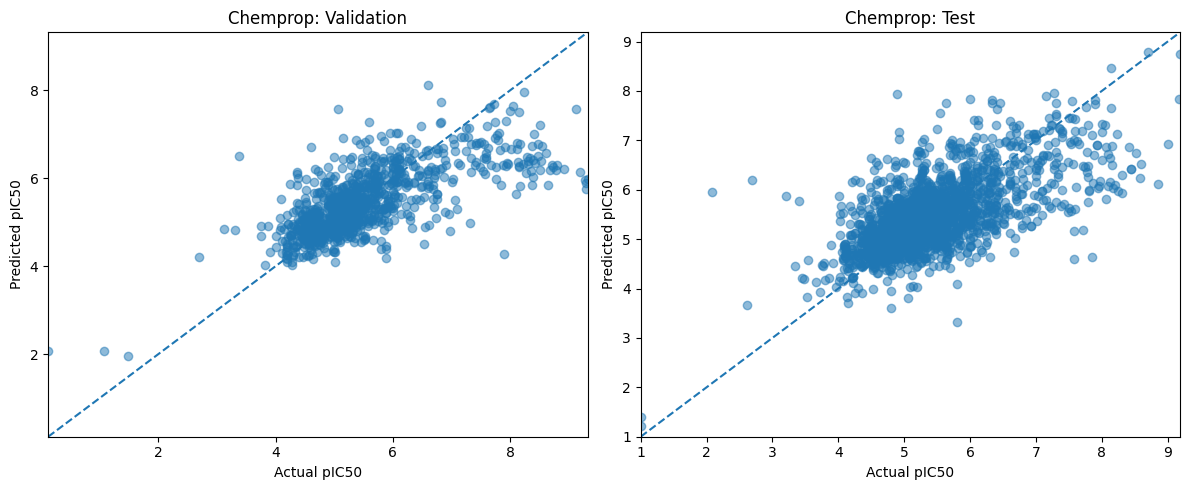

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, comparison, name in [
    (axes[0], val_comparison, "Validation"),
    (axes[1], test_comparison, "Test"),
]:
    actual = comparison["actual_pIC50"]
    predicted = comparison["predicted_pIC50"]

    ax.scatter(actual, predicted, alpha=0.5)
    lower = min(actual.min(), predicted.min())
    upper = max(actual.max(), predicted.max())

    ax.plot([lower, upper], [lower, upper], linestyle="--")
    ax.set_xlabel("Actual pIC50")
    ax.set_ylabel("Predicted pIC50")
    ax.set_title(f"Chemprop: {name}")
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)

plt.tight_layout()
plt.show()

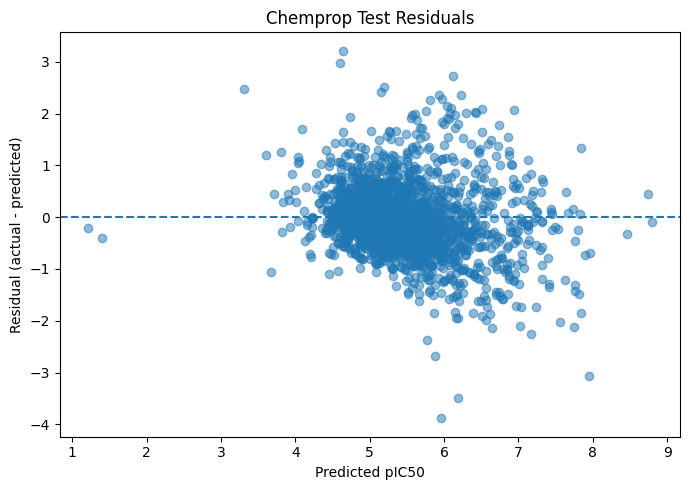

In [17]:
test_comparison["residual"] = (
    test_comparison["actual_pIC50"]
    - test_comparison["predicted_pIC50"]
)

plt.figure(figsize=(7, 5))
plt.scatter(
    test_comparison["predicted_pIC50"],
    test_comparison["residual"],
    alpha=0.5
)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted pIC50")
plt.ylabel("Residual (actual - predicted)")
plt.title("Chemprop Test Residuals")
plt.tight_layout()
plt.show()

In [18]:
RESULTS_DIR = "/kaggle/working/chemprop_regression/results"

import os
os.makedirs(RESULTS_DIR, exist_ok=True)

metrics_df.to_csv(
    f"{RESULTS_DIR}/regression_metrics.csv",
    index=False
)

val_comparison.to_csv(
    f"{RESULTS_DIR}/val_evaluated_predictions.csv",
    index=False
)

test_comparison.to_csv(
    f"{RESULTS_DIR}/test_evaluated_predictions.csv",
    index=False
)

print("Metrics and evaluated predictions saved.")

Metrics and evaluated predictions saved.
